In [13]:
import numpy as np

def steepest_descent(A, b, x0, tol=1e-10, max_iter=50000):
    x = x0.copy()
    r = b - A @ x
    norm_b = np.linalg.norm(b)
    rho = [np.linalg.norm(r) / norm_b]
    
    for k in range(max_iter):
        if rho[-1] <= tol:
            break
        alpha = (r @ r) / (r @ A @ r)
        x = x + alpha * r
        r = r - alpha * (A @ r)
        rho.append(np.linalg.norm(r) / norm_b)
        
    return x, rho, len(rho) - 1

In [19]:
A = np.loadtxt("A.dat",delimiter=',')

In [23]:
# Check symmetry
symmetry_check = np.linalg.norm(A - A.T)
print("||A - A^T||_2 =", symmetry_check)

# Setup x_true, b, and x0
x_true = np.ones(1600)
b = A @ x_true
x0 = np.zeros(1600)

||A - A^T||_2 = 0.0


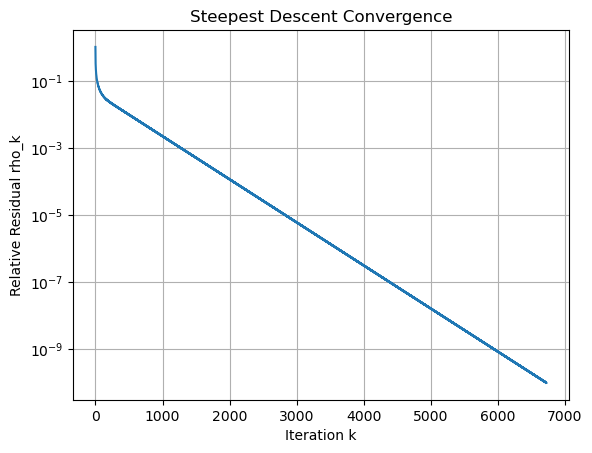

Iterations: 6722
Final rho: 9.961100344735253e-11


In [34]:
import matplotlib.pyplot as plt

# 1.steepest descent with existing variables
x_k, rho, k = steepest_descent(A, b, np.zeros(len(A)))

# 2. Semilog plot
plt.semilogy(rho)
plt.xlabel("Iteration k")
plt.ylabel("Relative Residual rho_k")
plt.title("Steepest Descent Convergence")
plt.grid(True)
plt.savefig("convergence.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Print the results
print("Iterations:", k)
print("Final rho:", rho[-1])

In [36]:
sol_error = np.linalg.norm(x_k - x_true) / np.linalg.norm(x_true)
print("sol_error =", sol_error)

sol_error = 1.9666802364412034e-09


In [40]:
# 2(a) Symmetric eigensolver
w, v = np.linalg.eigh(A)

lambda_min = w[0]
lambda_max = w[-1]
q_min = v[:, 0]
q_max = v[:, -1]

kappa = lambda_max / lambda_min

print("lambda_min =", lambda_min)
print("lambda_max =", lambda_max)
print("kappa_2(A) =", kappa)
print("Both eigenvalues positive?", lambda_min > 0 and lambda_max > 0)

lambda_min = 0.011736795265038909
lambda_max = 7.988263204734964
kappa_2(A) = 680.6170700216676
Both eigenvalues positive? True


In [42]:
# Problem 2(b)
x_star = q_max
b_star = A @ x_star
eta = 1e-4

print("||x_star||_2 =", np.linalg.norm(x_star))
print("||b_star||_2 =", np.linalg.norm(b_star))

||x_star||_2 = 1.0000000000000004
||b_star||_2 = 7.988263204734966


In [55]:
# Problem 2(c)
norm_b_star = np.linalg.norm(b_star)

#perturbations
db_max = eta * norm_b_star * q_max
db_min = eta * norm_b_star * q_min

rel_db_max = np.linalg.norm(db_max) / norm_b_star
rel_db_min = np.linalg.norm(db_min) / norm_b_star

print("Relative size db_max:", rel_db_max)
print("Relative size db_min:", rel_db_min)
print("Verified equal to eta?", np.isclose(rel_db_max, eta) and np.isclose(rel_db_min, eta))

Relative size db_max: 0.00010000000000000005
Relative size db_min: 9.999999999999995e-05
Verified equal to eta? True


In [57]:
# Problem 2(d)
tol_p2 = 1e-12
x0 = np.zeros(len(A))

# max perturbation direction
x_tilde_max, rho_max, k_max = steepest_descent(A, b_star + db_max, x0, tol=tol_p2)

# min perturbation direction
x_tilde_min, rho_min, k_min = steepest_descent(A, b_star + db_min, x0, tol=tol_p2)

print(f"Max direction iterations: {k_max}, final rho: {rho_max[-1]:.3e}")
print(f"Min direction iterations: {k_min}, final rho: {rho_min[-1]:.3e}")

Max direction iterations: 1, final rho: 4.233e-16
Min direction iterations: 7, final rho: 8.082e-13


In [53]:
# Problem 2(e)
norm_x_star = np.linalg.norm(x_star)

rel_dx_max = np.linalg.norm(x_tilde_max - x_star) / norm_x_star
rel_dx_min = np.linalg.norm(x_tilde_min - x_star) / norm_x_star

G_max = rel_dx_max / rel_db_max
G_min = rel_dx_min / rel_db_min

print("G_max =", G_max)
print("G_min =", G_min)

G_max = 1.0000000000013824
G_min = 680.6170699820251


In [51]:
# 2(f)
x_exact_max = (1 + eta) * q_max
x_exact_min = q_max + eta * kappa * q_min

err_max = np.linalg.norm(x_tilde_max - x_exact_max)
err_min = np.linalg.norm(x_tilde_min - x_exact_min)

print("Difference from exact max solution:", err_max)
print("Difference from exact min solution:", err_min)

Difference from exact max solution: 7.201484030883322e-16
Difference from exact min solution: 4.687821996702924e-12
